# CardiaScreen — exploratory review and scoring

This notebook reads the cleaned UCI table and the packaged model.
Training itself is `python -m cardiascreen.train`, which writes
`reports/metrics.json` and `models/heart_risk_model.joblib`.
Re-run that command before a full refresh.
The score is a coursework screening signal, not a diagnosis.


## Cohort balance

The four processed UCI files are one table. Site is kept for description and is not a model feature.


In [1]:
from pathlib import Path
import json
import pandas as pd

root = Path.cwd()
if not (root / "reports" / "metrics.json").exists():
    root = Path.cwd().parent
table = pd.read_csv(root / "data" / "processed" / "heart_disease_combined.csv")
summary = table.groupby("cohort")["target"].agg(rows="size", disease_rate="mean").round(3)
print(f"rows={len(table)} prevalence={table['target'].mean():.3f}")
print(summary.to_string())
print("missing fraction")
missing = (
    table.drop(columns=["target", "num"])
    .isna()
    .mean()
    .round(3)
    .sort_values(ascending=False)
    .head(8)
)
print(missing.to_string())


rows=920 prevalence=0.553
             rows  disease_rate
cohort                         
cleveland     303         0.459
hungarian     294         0.361
switzerland   123         0.935
va            200         0.745
missing fraction
ca          0.664
thal        0.528
slope       0.336
chol        0.220
fbs         0.098
oldpeak     0.067
trestbps    0.065
thalach     0.060


## Figures

The same files are embedded in the written report.


eda_cohort_balance.png
eda_missingness.png
eda_chest_pain.png
eda_correlation.png
model_roc.png
model_confusion.png
architecture.png


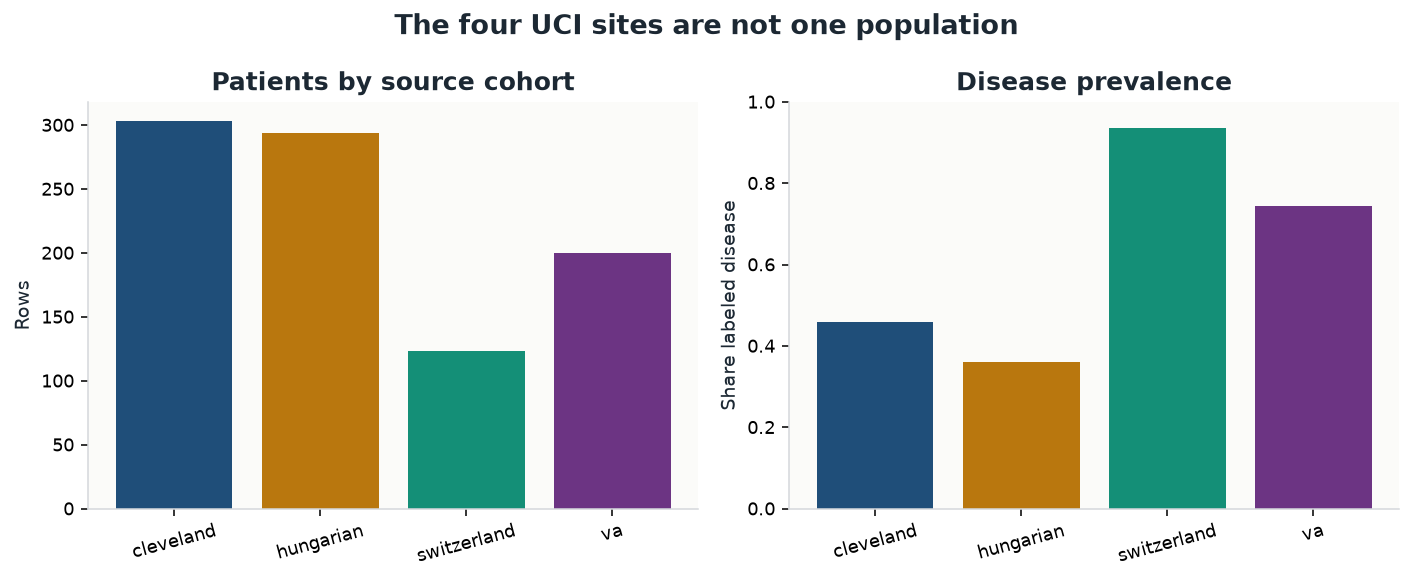

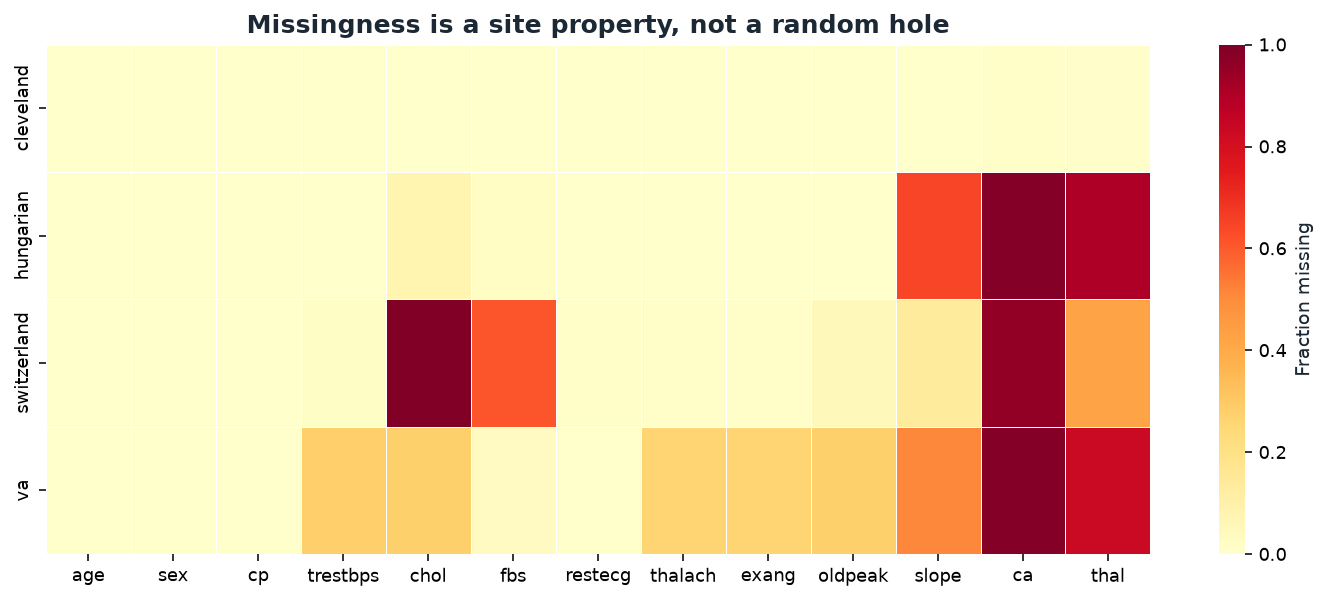

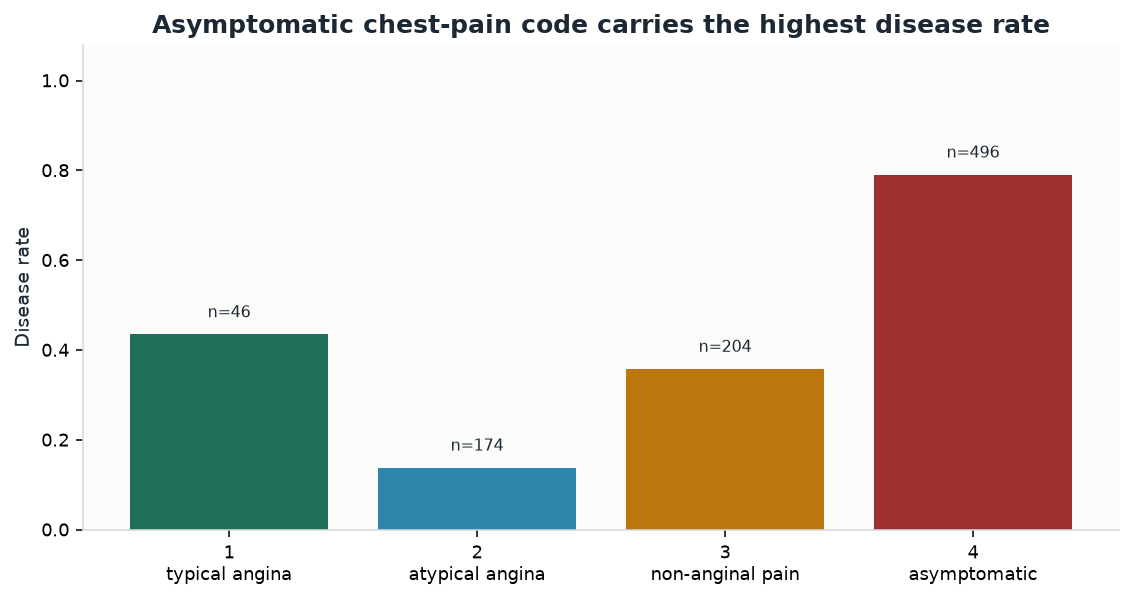

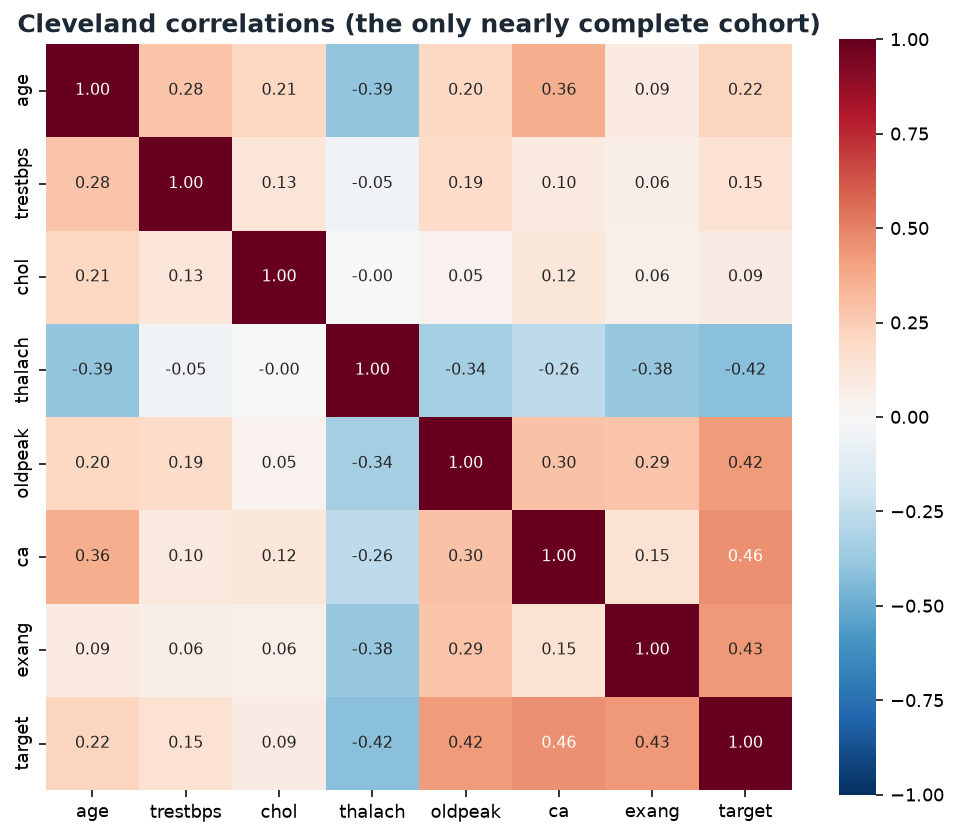

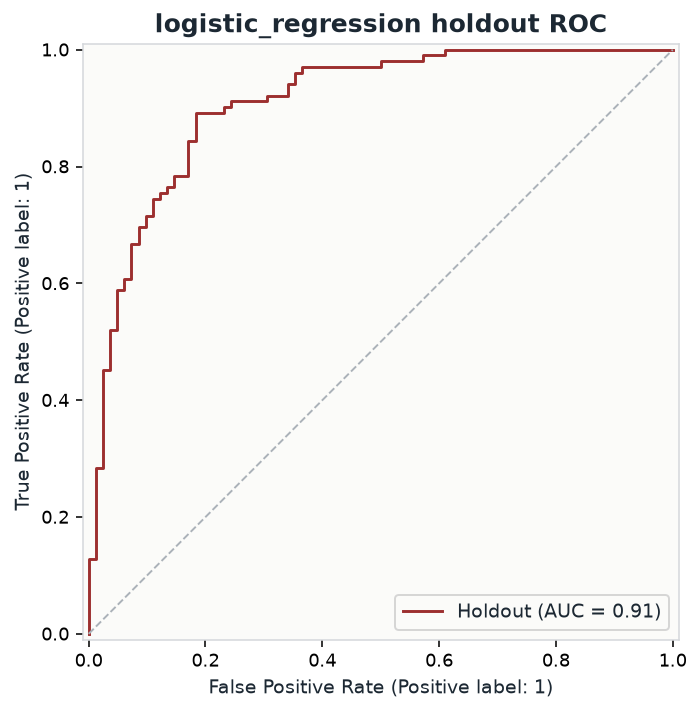

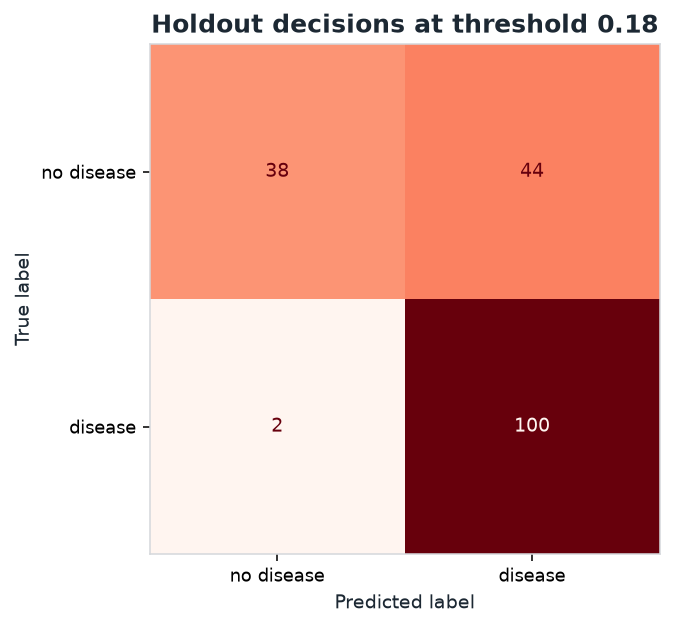

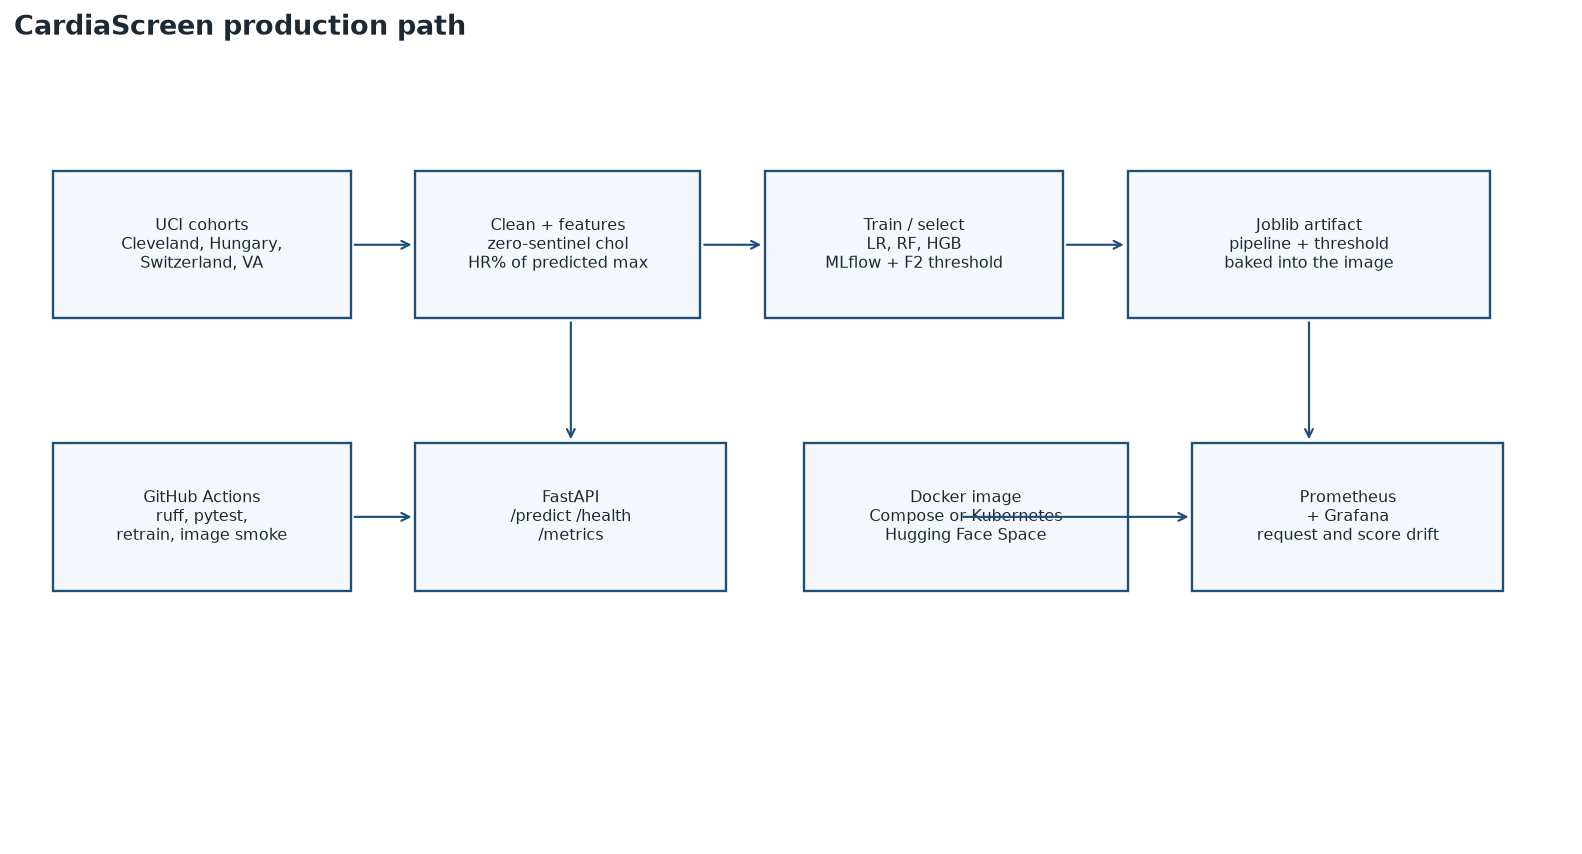

In [2]:
from IPython.display import Image, display
from pathlib import Path

root = Path.cwd()
if not (root / "reports" / "figures").exists():
    root = Path.cwd().parent
names = [
    "eda_cohort_balance.png",
    "eda_missingness.png",
    "eda_chest_pain.png",
    "eda_correlation.png",
    "model_roc.png",
    "model_confusion.png",
    "architecture.png",
]
for name in names:
    print(name)
    display(Image(filename=str(root / "reports" / "figures" / name)))


## Frozen experiment

Model choice used training-split ROC-AUC only.
The threshold maximizes F2 on training out-of-fold scores.


In [3]:
import json
from pathlib import Path

root = Path.cwd()
if not (root / "reports" / "metrics.json").exists():
    root = Path.cwd().parent
metrics = json.loads((root / "reports" / "metrics.json").read_text(encoding="utf-8"))
print("winner", metrics["model_name"], "threshold", round(metrics["threshold"], 2))
for row in metrics["leaderboard"]:
    print(f"{row['model_name']:24} cv_auc={row['cv_roc_auc']:.3f}  sd={row['cv_roc_auc_std']:.3f}")
holdout = metrics["holdout"]
print(
    "holdout",
    f"auc={holdout['roc_auc']:.3f}",
    f"recall={holdout['recall']:.3f}",
    f"precision={holdout['precision']:.3f}",
    f"accuracy={holdout['accuracy']:.3f}",
)


winner logistic_regression threshold 0.18
logistic_regression      cv_auc=0.895  sd=0.013
random_forest            cv_auc=0.881  sd=0.024
hist_gradient_boosting   cv_auc=0.873  sd=0.022
holdout auc=0.909 recall=0.980 precision=0.694 accuracy=0.750


## Sample scores

`ca` and `thal` can be omitted. Chest pain uses UCI codes 1 through 4.


In [4]:
import json
from pathlib import Path
import joblib

from cardiascreen.scoring import score_records

root = Path.cwd()
if not (root / "models" / "heart_risk_model.joblib").exists():
    root = Path.cwd().parent
artifact = joblib.load(root / "models" / "heart_risk_model.joblib")
for name in (
    "sample_request.json",
    "sample_request_low_risk.json",
    "sample_request_screening.json",
):
    payload = json.loads((root / "deploy" / name).read_text(encoding="utf-8"))
    decision = score_records(artifact, [payload])[0]
    print(name, decision["label"], decision["probability"], decision["risk_band"])


sample_request.json disease_signal 0.988089 very_high
sample_request_low_risk.json no_disease_signal 0.031318 low
sample_request_screening.json disease_signal 0.94923 very_high
